<div style="display: flex; background-color: RGB(34, 87, 60);" >
<h1 style="margin: auto; padding: 30px; color: white; ">ONLINE BOOKSHOP SALES ANALYSIS</h1>
</div>

<div style="background-color: RGB(128, 0, 32);" >
<h2 style="margin: auto; padding: 20px; color: white; ">Step 1 - Importing libraries and loading the files</h2>
</div>

<div style="border: 1px solid RGB(128, 0, 32);" >
<h3 style="margin: auto; padding: 20px; color: RGB(128, 0, 32); ">1.1 - Importing libraries</h3>
</div>

In [1]:
# Import pandas
import pandas as pd

In [2]:
# Import Plotly
import plotly.express as px
import plotly.graph_objects as go

In [3]:
# Import NumPy
import numpy as np

In [4]:
# Import Seaborn
import seaborn as sns

In [5]:
# Import Matplotlib
import matplotlib.pyplot as plt

<div style="border: 1px solid RGB(128, 0, 32);" >
<h3 style="margin: auto; padding: 20px; color: RGB(128, 0, 32); ">1.2 - Loading the files</h3>
</div>

In [6]:
# Load customers
df_customers = pd.read_csv(
    "../data/customers.csv",
    sep=";",
)
# Load products
df_products = pd.read_csv(
    "../data/products.csv",
    sep=";",
)
# Load transactions (zipped CSV, read directly by pandas)
df_transactions = pd.read_csv(
    "../data/transactions.zip",
    sep=";",
)

/tmp/ipykernel_439/2378465909.py:12: DtypeWarning: Columns (0: id_prod, 1: date, 2: session_id, 3: client_id) have mixed types. Specify dtype option on import or set low_memory=False.
  df_transactions = pd.read_csv(


<div style="background-color: RGB(128, 0, 32);" >
<h2 style="margin: auto; padding: 20px; color: white; ">Step 2 - Exploratory analysis of the files</h2>
</div>

<div style="border: 1px solid RGB(128, 0, 32);" >
<h3 style="margin: auto; padding: 20px; color: RGB(128, 0, 32); ">2.1 - Exploring customers.csv</h3>
</div>

In [7]:
# Shape of customers
df_customers.info()

<class 'pandas.DataFrame'>
RangeIndex: 8621 entries, 0 to 8620
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   client_id  8621 non-null   str  
 1   sex        8621 non-null   str  
 2   birth      8621 non-null   int64
dtypes: int64(1), str(2)
memory usage: 260.0 KB


In [8]:
# First 5 rows
df_customers.head(5)

,client_id,sex,birth
0,c_4410,f,1967
1,c_7839,f,1975
2,c_1699,f,1984
3,c_5961,f,1962
4,c_5320,m,1943


In [9]:
# Check for duplicated client_id
print(
    f"The client_id column contains {format(df_customers["client_id"].duplicated().sum())} duplicates"
)

The client_id column contains 0 duplicates


In [10]:
# Distinct values of sex
df_customers["sex"].unique()

<ArrowStringArray>
['f', 'm']
Length: 2, dtype: str

In [11]:
# Create the age column
df_customers["age"] = 2023 - df_customers["birth"]
df_customers["age"].describe()

count    8621.000000
mean       44.724394
std        16.917958
min        19.000000
25%        31.000000
50%        44.000000
75%        57.000000
max        94.000000
Name: age, dtype: float64

In [12]:
# New dataframe
df_customers.head(5)

,client_id,sex,birth,age
0,c_4410,f,1967,56
1,c_7839,f,1975,48
2,c_1699,f,1984,39
3,c_5961,f,1962,61
4,c_5320,m,1943,80


In [13]:
# Min and max age
print(f"Min age: {df_customers['age'].min()}")
print(f"Max age: {df_customers['age'].max()}")

Min age: 19
Max age: 94


Conclusion:
The customers file gives each customer's year of birth, sex and ID. The bookshop has 8,621 customers with an average age of 45. The youngest customer is 19 and the oldest 94. No outliers, duplicates or missing values: all values are consistent.

<div style="border: 1px solid RGB(128, 0, 32);" >
<h3 style="margin: auto; padding: 20px; color: RGB(128, 0, 32); ">2.2 - Exploring products.csv</h3>
</div>

In [14]:
# Shape of products
df_products.info()

<class 'pandas.DataFrame'>
RangeIndex: 3286 entries, 0 to 3285
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   id_prod  3286 non-null   str    
 1   price    3286 non-null   float64
 2   categ    3286 non-null   int64  
dtypes: float64(1), int64(1), str(1)
memory usage: 94.1 KB


In [15]:
# First 5 rows
df_products.head(5)

,id_prod,price,categ
0,0_1421,19.99,0
1,0_1368,5.13,0
2,0_731,17.99,0
3,1_587,4.99,1
4,0_1507,3.99,0


In [16]:
# Check for duplicated id_prod
print(
    f"The id_prod column contains {format(df_products["id_prod"].duplicated().sum())} duplicates"
)

The id_prod column contains 0 duplicates


In [17]:
# Book categories
df_products["categ"].unique()
print(f"There are {df_products['categ'].nunique()} book categories ")

There are 3 book categories 


In [18]:
# Min and max price
print(f"Min price: {df_products['price'].min()}")
print(f"Max price: {df_products['price'].max()}")

Min price: 0.62
Max price: 300.0


In [19]:
# Price statistics
df_products["price"].describe()

count    3286.000000
mean       21.863597
std        29.849786
min         0.620000
25%         6.990000
50%        13.075000
75%        22.990000
max       300.000000
Name: price, dtype: float64

Conclusion:
The products file gives each book's price, category and ID. The catalogue holds 3,286 products across 3 book categories. The mean price is €21.86, above the median of €13.07: the distribution is pulled up by expensive products. No missing values or duplicates.

<div style="border: 1px solid RGB(128, 0, 32);" >
<h3 style="margin: auto; padding: 20px; color: RGB(128, 0, 32); ">2.3 - Exploring transactions.csv</h3>
</div>

In [20]:
# Shape of transactions
df_transactions.info()

<class 'pandas.DataFrame'>
RangeIndex: 1048575 entries, 0 to 1048574
Data columns (total 4 columns):
 #   Column      Non-Null Count   Dtype
---  ------      --------------   -----
 0   id_prod     687534 non-null  str  
 1   date        687534 non-null  str  
 2   session_id  687534 non-null  str  
 3   client_id   687534 non-null  str  
dtypes: str(4)
memory usage: 62.1 MB


In [21]:
# First 5 rows
df_transactions.head(5)

,id_prod,date,session_id,client_id
0,0_1259,2021-03-01 00:01:07.843138,s_1,c_329
1,0_1390,2021-03-01 00:02:26.047414,s_2,c_664
2,0_1352,2021-03-01 00:02:38.311413,s_3,c_580
3,0_1458,2021-03-01 00:04:54.559692,s_4,c_7912
4,0_1358,2021-03-01 00:05:18.801198,s_5,c_2033


In [22]:
# Check for duplicates
print(f"The transactions file contains {df_transactions.duplicated().sum()} duplicates")

The transactions file contains 361040 duplicates


In [23]:
# Investigate duplicates
df_transactions[df_transactions.duplicated(keep=False)].head(10)

,id_prod,date,session_id,client_id
687534,NaN,NaN,NaN,NaN
687535,NaN,NaN,NaN,NaN
687536,NaN,NaN,NaN,NaN
687537,NaN,NaN,NaN,NaN
687538,NaN,NaN,NaN,NaN
687539,NaN,NaN,NaN,NaN
687540,NaN,NaN,NaN,NaN
687541,NaN,NaN,NaN,NaN
687542,NaN,NaN,NaN,NaN
687543,NaN,NaN,NaN,NaN


In [24]:
# Remove empty rows
df_transactions = df_transactions.dropna()

In [25]:
# Check the removal of empty rows
print(f"The transactions file contains {df_transactions.duplicated().sum()} duplicates")

The transactions file contains 0 duplicates


In [26]:
# Check that every client_id exists in customers
df_transactions["client_id"].isin(df_customers["client_id"]).all()

np.True_

In [27]:
# Check that every id_prod exists in products
df_transactions["id_prod"].isin(df_products["id_prod"]).all()

np.True_

Every customer ID and product ID in the transactions file exists in the customers and products files respectively.

In [28]:
# Convert date to datetime
df_transactions["date"] = pd.to_datetime(df_transactions["date"])

In [29]:
# Time frame of the analysis
print(
    f"First transaction: {df_transactions['date'].min()}; last transaction: {df_transactions['date'].max()}"
)

First transaction: 2021-03-01 00:01:07.843138; last transaction: 2023-02-28 23:58:30.792755


Conclusion:
The transactions file lists the purchases made by customers, their sessions and the books bought. The date column was converted to datetime, and the duplicates and empty rows, most likely created by the export, were removed. Customer and product IDs are consistent with the two other files. The file covers exactly two years of transactions.

<div style="background-color: RGB(128, 0, 32);" >
<h2 style="margin: auto; padding: 20px; color: white; ">Step 3 - Joining the files</h2>
</div>

<div style="border: 1px solid RGB(128, 0, 32);" >
<h3 style="margin: auto; padding: 20px; color: RGB(128, 0, 32); ">3.1 - Joining transactions and products</h3>
</div>

In [30]:
# Join transactions and products
df_merge_transactions_products = pd.merge(
    df_transactions, df_products, on="id_prod", how="outer", indicator=True
)

In [31]:
# Check the join
print(df_merge_transactions_products["_merge"].value_counts())

_merge
both          687534
right_only        21
left_only          0
Name: count, dtype: int64


In [32]:
# Show the 21 unmatched rows
df_merge_transactions_products[df_merge_transactions_products["_merge"] == "right_only"]

,id_prod,date,session_id,client_id,price,categ,_merge
6073,0_1014,NaT,NaN,NaN,1.15,0,right_only
6511,0_1016,NaT,NaN,NaN,35.06,0,right_only
8723,0_1025,NaT,NaN,NaN,24.99,0,right_only
21687,0_1062,NaT,NaN,NaN,20.08,0,right_only
40971,0_1119,NaT,NaN,NaN,2.99,0,right_only
94245,0_1318,NaT,NaN,NaN,20.92,0,right_only
297077,0_1620,NaT,NaN,NaN,0.80,0,right_only
299185,0_1624,NaT,NaN,NaN,24.50,0,right_only
311123,0_1645,NaT,NaN,NaN,2.99,0,right_only
323013,0_1780,NaT,NaN,NaN,1.67,0,right_only


In [33]:
# Keep the 21 references that were never sold in a separate dataframe
df_jamais_vendus = df_merge_transactions_products[
    df_merge_transactions_products["_merge"] == "right_only"
]

In [34]:
# Remove the 21 unmatched products
df_merge_transactions_products = df_merge_transactions_products[
    df_merge_transactions_products["_merge"] == "both"
]

In [35]:
# Drop the merge column
df_merge_transactions_products = df_merge_transactions_products.drop(columns="_merge")

Conclusion:
When joining the two files, 21 rows of the products file had no match in the transactions: these products were never sold. They were set aside in a separate dataframe and removed from the join.

<div style="border: 1px solid RGB(128, 0, 32);" >
<h3 style="margin: auto; padding: 20px; color: RGB(128, 0, 32); ">3.2 - Joining with customers</h3>
</div>

In [36]:
# Join with customers
df_merge_transaction_products_customers = pd.merge(
    df_merge_transactions_products,
    df_customers,
    on="client_id",
    how="outer",
    indicator=True,
)

In [37]:
# Check the join
print(df_merge_transaction_products_customers["_merge"].value_counts())

_merge
both          687534
right_only        21
left_only          0
Name: count, dtype: int64


In [38]:
# Show the 21 unmatched rows
df_merge_transaction_products_customers[
    df_merge_transaction_products_customers["_merge"] == "right_only"
]

,id_prod,date,session_id,client_id,price,categ,sex,birth,age,_merge
18399,NaN,NaT,NaN,c_1223,NaN,NaN,m,1963,60,right_only
167262,NaN,NaT,NaN,c_2706,NaN,NaN,f,1967,56,right_only
191551,NaN,NaT,NaN,c_3017,NaN,NaN,f,1992,31,right_only
225851,NaN,NaT,NaN,c_3443,NaN,NaN,m,1959,64,right_only
240172,NaN,NaT,NaN,c_3526,NaN,NaN,m,1956,67,right_only
261001,NaN,NaT,NaN,c_3789,NaN,NaN,f,1997,26,right_only
282271,NaN,NaT,NaN,c_4086,NaN,NaN,f,1992,31,right_only
305952,NaN,NaT,NaN,c_4358,NaN,NaN,m,1999,24,right_only
309172,NaN,NaT,NaN,c_4406,NaN,NaN,f,1998,25,right_only
312791,NaN,NaT,NaN,c_4447,NaN,NaN,m,1956,67,right_only


In [39]:
# Keep the 21 customers who never bought anything in a separate dataframe
df_clients_sans_achats = df_merge_transaction_products_customers[
    df_merge_transaction_products_customers["_merge"] == "right_only"
]

In [40]:
# Remove the 21 unmatched customers
df_merge_transaction_products_customers = df_merge_transaction_products_customers[
    df_merge_transaction_products_customers["_merge"] == "both"
]

In [41]:
# Drop the merge column
df_merge_transaction_products_customers = df_merge_transaction_products_customers.drop(
    columns="_merge"
)

In [42]:
# Final joined dataframe
df_merge_transaction_products_customers.info()

<class 'pandas.DataFrame'>
Index: 687534 entries, 0 to 687554
Data columns (total 9 columns):
 #   Column      Non-Null Count   Dtype         
---  ------      --------------   -----         
 0   id_prod     687534 non-null  str           
 1   date        687534 non-null  datetime64[us]
 2   session_id  687534 non-null  str           
 3   client_id   687534 non-null  str           
 4   price       687534 non-null  float64       
 5   categ       687534 non-null  float64       
 6   sex         687534 non-null  str           
 7   birth       687534 non-null  int64         
 8   age         687534 non-null  int64         
dtypes: datetime64[us](1), float64(2), int64(2), str(4)
memory usage: 65.9 MB


Conclusion:
When joining the two files, 21 rows of the customers file had no match: these customers never bought anything. They were set aside in a separate dataframe and removed from the join.
The final dataframe has 9 columns and 687,534 rows.

<div style="border: 1px solid RGB(128, 0, 32);" >
<h3 style="margin: auto; padding: 20px; color: RGB(128, 0, 32); ">3.3 - Exploring the joined dataset</h3>
</div>

In [43]:
# Orders per customer
achats_par_client = df_merge_transaction_products_customers.groupby("client_id")[
    "session_id"
].nunique()
print(achats_par_client.sort_values(ascending=False).head(10))

client_id
c_1609    10997
c_3454     5571
c_4958     3851
c_6714     2620
c_8526      167
c_2265      165
c_1637      165
c_669       163
c_8510      162
c_5602      161
Name: session_id, dtype: int64


In [44]:
# Distribution of orders per customer
achats_par_client = achats_par_client.reset_index()
fig = px.box(
    achats_par_client,
    y="session_id",
    hover_name="client_id",
    title="Orders per customer",
)
fig.update_layout(
    yaxis_title="Total orders",
    plot_bgcolor="white",
    xaxis=dict(showgrid=False),
    yaxis=dict(showgrid=False),
    showlegend=False,
)
fig.show()

In [45]:
# Revenue per customer
ca_par_client = df_merge_transaction_products_customers.groupby("client_id")[
    "price"
].sum()
print(ca_par_client.sort_values(ascending=False).head(10))

client_id
c_1609    326039.89
c_4958    290227.03
c_6714    153918.60
c_3454    114110.57
c_1570      5285.82
c_3263      5276.87
c_2140      5260.18
c_2899      5214.05
c_7319      5155.77
c_7959      5135.75
Name: price, dtype: float64


In [46]:
# Distribution of revenue per customer
ca_par_client = ca_par_client.reset_index()
fig = px.box(
    ca_par_client,
    y="price",
    hover_name="client_id",
    title="Revenue per customer",
)
fig.update_layout(
    yaxis_title="Total revenue (€)",
    plot_bgcolor="white",
    xaxis=dict(showgrid=False),
    yaxis=dict(showgrid=False),
    showlegend=False,
)
fig.show()

In [47]:
# Set aside the 4 customers with abnormal order counts and revenue
clients_anormaux = ["c_1609", "c_3454", "c_4958", "c_6714"]
df_clients_ventes_anormales = df_merge_transaction_products_customers[
    df_merge_transaction_products_customers["client_id"].isin(clients_anormaux)
]

In [48]:
# Remove these 4 customers from the main dataset
df_merge_transaction_products_customers = df_merge_transaction_products_customers[
    ~df_merge_transaction_products_customers["client_id"].isin(clients_anormaux)
]

Conclusion:
Exploring the joined file revealed 4 customers with abnormal sales volumes and revenue compared with all other customers, confirmed by the revenue and order counts per customer and visually by the boxplots. They are treated as B2B customers and analysed separately later. They were set aside in a separate dataframe and removed from the main dataset so as not to distort the analyses.

<div style="background-color: RGB(128, 0, 32);" >
<h2 style="margin: auto; padding: 20px; color: white; ">Step 4 - Revenue analysis</h2>
</div>

<div style="border: 1px solid RGB(128, 0, 32);" >
<h3 style="margin: auto; padding: 20px; color: RGB(128, 0, 32); ">4.1 - Revenue per year</h3>
</div>

In [49]:
# Yearly and total revenue
ca_mars_2021_2022 = df_merge_transaction_products_customers[
    df_merge_transaction_products_customers["date"] < "2022-03-01"
]["price"].sum()
ca_mars_2022_2023 = df_merge_transaction_products_customers[
    df_merge_transaction_products_customers["date"] >= "2022-03-01"
]["price"].sum()
ca_total_hors_btob = ca_mars_2021_2022 + ca_mars_2022_2023
evolution_ca = ca_mars_2022_2023 - ca_mars_2021_2022
print(f"Year 1 revenue (March to February): {ca_mars_2021_2022:,.2f} €")
print(f"Year 2 revenue (March to February): {ca_mars_2022_2023:,.2f} €")
print(
    f"Total revenue since the start of online sales: {ca_total_hors_btob:,.2f} €"
)
print(
    f"Revenue grew by {evolution_ca:,.2f} € from year 1 to year 2"
)

Year 1 revenue (March to February): 5,566,713.35 €
Year 2 revenue (March to February): 5,576,653.66 €
Total revenue since the start of online sales: 11,143,367.01 €
Revenue grew by 9,940.31 € from year 1 to year 2


In [50]:
# Compare the two years
fig = px.bar(
    x=["Year 1 (03/21-02/22)", "Year 2 (03/22-02/23)"],
    y=[ca_mars_2021_2022, ca_mars_2022_2023],
    color=["Year 1", "Year 2"],
    title="Yearly revenue",
    color_discrete_sequence=["#2E8B57", "#4169E1"],
)
fig.update_layout(
    xaxis_title="",
    yaxis_title="Revenue (€)",
    plot_bgcolor="white",
    xaxis=dict(showgrid=False),
    yaxis=dict(showgrid=False),
    showlegend=False,
)
fig.show()

Conclusion:
The two rolling 12-month revenues are extremely close: €5.57M in year 1 and a slight increase to €5.58M in year 2. Revenue is very stable from one year to the next; moving averages will show whether seasonal patterns or monthly dynamics exist.

<div style="border: 1px solid RGB(128, 0, 32);" >
<h3 style="margin: auto; padding: 20px; color: RGB(128, 0, 32); ">4.2 - Revenue over time with moving averages</h3>
</div>

In [51]:
# Daily revenue
ca_jour = (
    df_merge_transaction_products_customers.groupby(
        df_merge_transaction_products_customers["date"].dt.date
    )["price"]
    .sum()
    .reset_index()
)

In [52]:
# Rename columns
ca_jour.columns = ["date", "CA"]

In [53]:
# Moving averages
ca_jour["MM7"] = ca_jour["CA"].rolling(window=7).mean()
ca_jour["MM30"] = ca_jour["CA"].rolling(window=30).mean()
ca_jour["MM90"] = ca_jour["CA"].rolling(window=90).mean()
ca_jour["MM180"] = ca_jour["CA"].rolling(window=180).mean()
ca_jour["MM365"] = ca_jour["CA"].rolling(window=365).mean()

In [54]:
# Chart
fig = go.Figure()
fig.add_trace(
    go.Scatter(
        x=ca_jour["date"],
        y=ca_jour["CA"],
        mode="lines",
        name="Daily revenue",
        line=dict(color="#2E8B57", width=0.5),
    )
)
fig.add_trace(
    go.Scatter(
        x=ca_jour["date"],
        y=ca_jour["MM30"],
        mode="lines",
        name=("30-day average"),
        line=dict(color="#A3334D", width=2),
    )
)
fig.add_trace(
    go.Scatter(
        x=ca_jour["date"],
        y=ca_jour["MM90"],
        mode="lines",
        name=("90-day average"),
        line=dict(color="#4169E1", width=2),
    )
)
fig.update_layout(
    title="Revenue with moving averages",
    xaxis_title="Date",
    yaxis_title="Revenue (€)",
    plot_bgcolor="white",
    xaxis=dict(showgrid=False),
    yaxis=dict(showgrid=False),
    width=1550,
    height=500,
)
fig.show()

Conclusion:
Daily revenue alternates frequently between peaks and dips, probably due to catch-up effects, promotions or days of the week. It broadly ranges between €12,000 and €20,000, and moving averages help reveal the underlying trends. The 30-day average shows a marked seasonality, with dips in July and November 2021 and peaks in October 2021 and February 2022. The 90-day average shows an upward trend until March 2022, followed by a plateau of daily revenue around €15,000.

<div style="border: 1px solid RGB(128, 0, 32);" >
<h3 style="margin: auto; padding: 20px; color: RGB(128, 0, 32); ">4.3 - Revenue by category</h3>
</div>

In [55]:
# Convert categ to int for the chart
df_merge_transaction_products_customers["categ"] = (
    df_merge_transaction_products_customers["categ"].astype(int)
)

In [56]:
# Revenue by category
ca_categ = df_merge_transaction_products_customers.groupby("categ")["price"].sum()

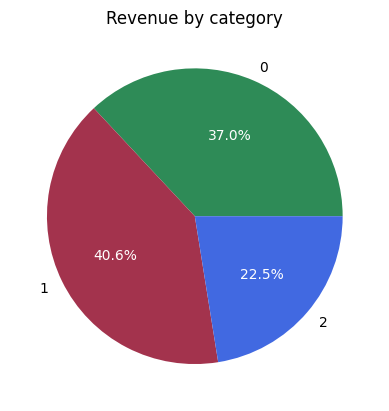

In [57]:
# Pie chart
nom_categ = {0: "0", 1: "1", 2: "2"}
couleurs = ["#2E8B57", "#A3334D", "#4169E1"]
wedges, texts, autotexts = plt.pie(
    ca_categ, labels=ca_categ.index, autopct="%1.1f%%", colors=couleurs
)
for t in autotexts:
    t.set_color("white"),
for t in texts:
    t.set_color("black")
plt.title("Revenue by category")
plt.show()

Conclusion:
Category 1 leads revenue with 40%, followed by category 0 at 37% and category 2 at 23%. Categories 0 and 1 are very close, while category 2 weighs clearly less. At first sight the catalogue looks fairly balanced, but the number of references per category needs checking to make sure none benefits from a volume effect.

<div style="border: 1px solid RGB(128, 0, 32);" >
<h3 style="margin: auto; padding: 20px; color: RGB(128, 0, 32); ">4.4 - Catalogue by category</h3>
</div>

In [58]:
# References per category
ref_categ = df_merge_transaction_products_customers.groupby("categ")[
    "id_prod"
].nunique()

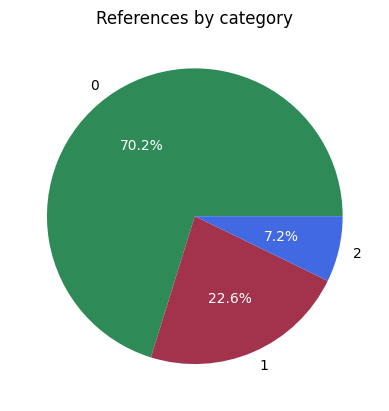

In [59]:
# Pie chart
nom_categ = {0: "0", 1: "1", 2: "2"}
couleurs = ["#2E8B57", "#A3334D", "#4169E1"]
wedges, texts, autotexts = plt.pie(
    ref_categ, labels=ref_categ.index, autopct="%1.1f%%", colors=couleurs
)
for t in autotexts:
    t.set_color("white"),
for t in texts:
    t.set_color("black")
plt.title("References by category")
plt.show()

Conclusion:
Comparing the two breakdowns shows that revenue is not proportional to the number of references. Category 0 holds 70% of the catalogue but generates only 37% of revenue. Category 1, on the other hand, brings in more than a third of revenue with only 23% of the catalogue. Category 2 is the most efficient: with very few references, it generates nearly a quarter of total revenue. The catalogue is therefore not balanced but shows strong differences in profitability between categories. Let's check whether price levels explain this.

<div style="border: 1px solid RGB(128, 0, 32);" >
<h3 style="margin: auto; padding: 20px; color: RGB(128, 0, 32); ">4.5 - Average price by category</h3>
</div>

In [60]:
# Average price by category
prix_moyen_par_categ = (
    df_merge_transaction_products_customers.groupby("categ")["price"].mean().round(2)
)

In [61]:
# Average price by category
fig = px.bar(
    x=prix_moyen_par_categ.index.astype(str),
    y=prix_moyen_par_categ.values,
    title="Average price by category",
    color=prix_moyen_par_categ.index.astype(str),
    color_discrete_sequence=["#2E8B57", "#A3334D", "#4169E1"],
)
fig.update_layout(
    xaxis_title="Category",
    yaxis_title="Average price (€)",
    plot_bgcolor="white",
    xaxis=dict(showgrid=False),
    yaxis=dict(showgrid=False),
    showlegend=False,
)
fig.show()

Conclusion:
Category 2 has an average price of €76, against €20.50 for category 1 and €10.60 for category 0. This confirms the previous hypothesis: the more a category weighs in the catalogue, the lower its average price.
It also gives a hierarchy of categories: category 2 = premium products, category 1 = mid-range products, category 0 = entry-level products. This hierarchy is useful for the customer and catalogue analyses.

<div style="border: 1px solid RGB(128, 0, 32);" >
<h3 style="margin: auto; padding: 20px; color: RGB(128, 0, 32); ">4.6 - Revenue by category over time</h3>
</div>

In [62]:
# Monthly revenue by category
ca_categ_mois = df_merge_transaction_products_customers.groupby(
    [df_merge_transaction_products_customers["date"].dt.to_period("M"), "categ"]
)["price"].sum()
ca_categ_mois = ca_categ_mois.unstack()
ca_categ_mois.index = ca_categ_mois.index.to_timestamp()

In [63]:
# Monthly revenue by category over time
fig = go.Figure()

fig.add_trace(
    go.Scatter(
        x=ca_categ_mois.index.astype(str),
        y=ca_categ_mois[0],
        mode="lines+markers",
        name="Category 0",
        line=dict(color="#2E8B57"),
        marker=dict(size=8),
    )
)

fig.add_trace(
    go.Scatter(
        x=ca_categ_mois.index.astype(str),
        y=ca_categ_mois[1],
        mode="lines+markers",
        name="Category 1",
        line=dict(color="#A3334D"),
        marker=dict(size=8),
    )
)

fig.add_trace(
    go.Scatter(
        x=ca_categ_mois.index.astype(str),
        y=ca_categ_mois[2],
        mode="lines+markers",
        name="Category 2",
        line=dict(color="#4169E1"),
        marker=dict(size=8),
    )
)

fig.update_layout(
    title="Monthly revenue by category",
    xaxis_title="Month",
    yaxis_title="Revenue (€)",
    plot_bgcolor="white",
    xaxis=dict(showgrid=True),
    yaxis=dict(showgrid=True, gridcolor="Lightgray"),
)
fig.show()

Conclusion:
The curves confirm the two pie charts: despite a catalogue dominated by category 0, category 1 consistently generates the most revenue over time. Category 2, with only 7% of the catalogue, keeps a stable and significant revenue, confirming its high profitability per reference. The revenue split between categories stays stable over the two years: the gaps are not linked to a specific period or to seasonality, but to a structural feature of the catalogue.

<div style="background-color: RGB(128, 0, 32);" >
<h2 style="margin: auto; padding: 20px; color: white; ">Step 5 - Sales activity</h2>
</div>

<div style="border: 1px solid RGB(128, 0, 32);" >
<h3 style="margin: auto; padding: 20px; color: RGB(128, 0, 32); ">5.1 - Customers per month</h3>
</div>

In [64]:
# Customers per month
clients_par_mois = df_merge_transaction_products_customers.groupby(
    df_merge_transaction_products_customers["date"].dt.to_period("M")
)["client_id"].nunique()
print(
    f"Year 1 average: {clients_par_mois[clients_par_mois.index < '2022-03'].mean():.0f} customers per month"
)
print(
    f"Year 2 average: {clients_par_mois[clients_par_mois.index >= '2022-03'].mean():.0f} customers per month"
)

Year 1 average: 5757 customers per month
Year 2 average: 5754 customers per month


In [65]:
# Customers per month over time
fig = px.line(
    x=clients_par_mois.index.astype(str),
    y=clients_par_mois.values,
    markers=True,
    title="Customers per month",
)
fig.update_traces(line_color="#A3334D", marker=dict(size=8))
fig.update_layout(
    xaxis_title="Month",
    yaxis_title="Customers",
    plot_bgcolor="white",
    xaxis=dict(showgrid=False),
    yaxis=dict(gridcolor="lightgray"),
)
fig.show()

Conclusion:
The number of customers follows a seasonal pattern, with a peak in October 2021 at nearly 6,200 unique customers, before stabilising around 5,700 customers a month in 2022. A decline begins in early 2023.

<div style="border: 1px solid RGB(128, 0, 32);" >
<h3 style="margin: auto; padding: 20px; color: RGB(128, 0, 32); ">5.2 - Orders per month</h3>
</div>

In [66]:
# Orders per month
transactions_par_mois = df_merge_transaction_products_customers.groupby(
    df_merge_transaction_products_customers["date"].dt.to_period("M")
)["session_id"].nunique()
print(
    f"Year 1 average: {transactions_par_mois[transactions_par_mois.index < '2022-03'].mean():.0f} orders per month"
)
print(
    f"Year 2 average: {transactions_par_mois[transactions_par_mois.index >= '2022-03'].mean():.0f} orders per month"
)

Year 1 average: 13422 orders per month
Year 2 average: 13454 orders per month


In [67]:
# Orders per month over time
fig = px.line(
    x=transactions_par_mois.index.astype(str),
    y=transactions_par_mois.values,
    markers=True,
    title="Orders per month",
)
fig.update_traces(line_color="#2E8B57", marker=dict(size=8))
fig.update_layout(
    xaxis_title="Month",
    yaxis_title="Orders",
    plot_bgcolor="white",
    xaxis=dict(showgrid=False),
    yaxis=dict(gridcolor="lightgray"),
)
fig.show()

Conclusion:
The number of orders follows the same dynamic: a dip in summer 2021, a rise until December 2021, stabilisation between 13,000 and 14,000 orders a month in 2022, then a decline from January 2023.

<div style="border: 1px solid RGB(128, 0, 32);" >
<h3 style="margin: auto; padding: 20px; color: RGB(128, 0, 32); ">5.3 - Purchase frequency per month</h3>
</div>

In [68]:
# Purchase frequency per month
frequence_achats_mois = transactions_par_mois / clients_par_mois
print(
    f"Year 1 average: {frequence_achats_mois[frequence_achats_mois.index < '2022-03'].mean():.2f} orders per customer per month"
)
print(
    f"Year 2 average: {frequence_achats_mois[frequence_achats_mois.index >= '2022-03'].mean():.2f} orders per customer per month"
)

Year 1 average: 2.33 orders per customer per month
Year 2 average: 2.34 orders per customer per month


In [69]:
# Purchase frequency over time
fig = px.line(
    x=frequence_achats_mois.index.astype(str),
    y=frequence_achats_mois.values,
    markers=True,
    title="Purchase frequency per month",
)
fig.update_traces(line_color="#4169E1", marker=dict(size=8))
fig.update_layout(
    xaxis_title="Month",
    yaxis_title="Frequency",
    plot_bgcolor="white",
    xaxis=dict(showgrid=False),
    yaxis=dict(gridcolor="lightgray"),
)
fig.show()

Conclusion:
Purchase frequency follows the same seasonal pattern and stabilises around 2.35 in 2022: on average, a customer buys about twice a month, a sign of a loyal customer base with regular habits. This is explored further in the customer analysis.

<div style="border: 1px solid RGB(128, 0, 32);" >
<h3 style="margin: auto; padding: 20px; color: RGB(128, 0, 32); ">5.4 - Books sold per month</h3>
</div>

In [70]:
# Books sold per month
produits_vendus_par_mois = df_merge_transaction_products_customers.groupby(
    df_merge_transaction_products_customers["date"].dt.to_period("M")
)["id_prod"].count()
print(
    f"Year 1 average: {produits_vendus_par_mois[produits_vendus_par_mois.index < '2022-03'].mean():.0f} books sold per month"
)
print(
    f"Year 2 average: {produits_vendus_par_mois[produits_vendus_par_mois.index >= '2022-03'].mean():.0f} books sold per month"
)

Year 1 average: 26855 books sold per month
Year 2 average: 26540 books sold per month


In [71]:
# Customers per month over time
fig = px.line(
    x=produits_vendus_par_mois.index.astype(str),
    y=produits_vendus_par_mois.values,
    markers=True,
    title="Books sold per month",
)
fig.update_traces(line_color="#A3334D", marker=dict(size=8))
fig.update_layout(
    xaxis_title="Month",
    yaxis_title="Books",
    plot_bgcolor="white",
    xaxis=dict(showgrid=False),
    yaxis=dict(gridcolor="lightgray"),
)
fig.show()

Conclusion:
Books sold per month follow the same seasonal pattern, with a dip in summer 2021 (23,000) and a peak in September 2021 (31,000), probably due to the holidays and the start of the school year. Another peak appears in December 2021 (30,000) with the end-of-year holidays, before volume stabilises around 27,000 books a month in 2022, then declines from January 2023 to only 23,000 books in February 2023.

<div style="border: 1px solid RGB(128, 0, 32);" >
<h3 style="margin: auto; padding: 20px; color: RGB(128, 0, 32); ">5.5 - Average books bought per customer</h3>
</div>

In [72]:
# Average books bought per customer
produits_moyen_par_client = produits_vendus_par_mois / clients_par_mois
print(
    f"Year 1 average: {produits_moyen_par_client[produits_moyen_par_client.index < '2022-03'].mean():.0f} books per customer per month"
)
print(
    f"Year 2 average: {produits_moyen_par_client[produits_moyen_par_client.index >= '2022-03'].mean():.0f} books per customer per month"
)

Year 1 average: 5 books per customer per month
Year 2 average: 5 books per customer per month


In [73]:
# Average books bought per customer over time
fig = px.line(
    x=produits_moyen_par_client.index.astype(str),
    y=produits_moyen_par_client.values,
    markers=True,
    title="Average books bought per customer",
)
fig.update_traces(line_color="#2E8B57", marker=dict(size=8))
fig.update_layout(
    xaxis_title="Month",
    yaxis_title="Books",
    plot_bgcolor="white",
    xaxis=dict(showgrid=False),
    yaxis=dict(gridcolor="lightgray"),
)
fig.show()

Conclusion:
Each customer buys about 5 books a month on average, a stable figure in 2022 and 2023. The same seasonal patterns appear, with a dip in summer 2021 and peaks at 5.4 in September 2021 and 5.1 in December 2021.

<div style="border: 1px solid RGB(128, 0, 32);" >
<h3 style="margin: auto; padding: 20px; color: RGB(128, 0, 32); ">5.6 - Average basket</h3>
</div>

In [74]:
# Average basket per month
panier_par_session = df_merge_transaction_products_customers.groupby(
    [df_merge_transaction_products_customers["date"].dt.to_period("M"), "session_id"]
)["price"].sum()
panier_moyen_mois = panier_par_session.groupby(level=0).mean().round(2)
print(
    f"Year 1 average: {panier_moyen_mois[panier_moyen_mois.index < '2022-03'].mean():.2f} €"
)
print(
    f"Year 2 average: {panier_moyen_mois[panier_moyen_mois.index >= '2022-03'].mean():.2f} €"
)

Year 1 average: 34.58 €
Year 2 average: 34.54 €


In [75]:
# Average basket over time
fig = px.line(
    x=panier_moyen_mois.index.astype(str),
    y=panier_moyen_mois.values,
    markers=True,
    title="Average basket over time",
)
fig.update_traces(line_color="#4169E1", marker=dict(size=8))
fig.update_layout(
    xaxis_title="Month",
    yaxis_title="Average basket (€)",
    plot_bgcolor="white",
    xaxis=dict(showgrid=False),
    yaxis=dict(gridcolor="lightgray"),
)
fig.show()

Conclusion:
The average basket is fairly stable over most of 2022. Unlike the other indicators, it rises from December 2021 to February 2022, peaking at almost €37, while all other indicators were falling. The lowest average basket is in October 2021, the month with the most customers. This could be a dilution effect: busy periods attract occasional buyers with smaller baskets, while quieter periods leave the loyal customers, whose average basket stays between €34 and €35. This is checked in the customer analysis.

<div style="border: 1px solid RGB(128, 0, 32);" >
<h3 style="margin: auto; padding: 20px; color: RGB(128, 0, 32); ">5.7 - Average basket by category</h3>
</div>

In [76]:
# Average basket by category
panier_moyen_categorie = (
    df_merge_transaction_products_customers.groupby(["categ", "session_id"])["price"]
    .sum()
    .groupby(level=0)
    .mean()
    .round(2)
)

In [77]:
# Average basket by category
fig = px.bar(
    x=panier_moyen_categorie.index.astype(str),
    y=panier_moyen_categorie.values,
    title="Average basket by category",
    color=panier_moyen_categorie.index.astype(str),
    color_discrete_sequence=["#2E8B57", "#A3334D", "#4169E1"],
)
fig.update_layout(
    xaxis_title="Category",
    yaxis_title="Average basket (€)",
    plot_bgcolor="white",
    xaxis=dict(showgrid=False),
    yaxis=dict(showgrid=False),
    showlegend=False,
)
fig.show()

Conclusion:
The average basket by category logically reflects the price gaps between categories: almost €20 for entry-level category 0, €26 for category 1 and €91 for category 2. The more expensive the category, the larger the basket.

<div style="background-color: RGB(128, 0, 32);" >
<h2 style="margin: auto; padding: 20px; color: white; ">Step 6 - Catalogue analysis</h2>
</div>

<div style="border: 1px solid RGB(128, 0, 32);" >
<h3 style="margin: auto; padding: 20px; color: RGB(128, 0, 32); ">6.1 - Sales by revenue</h3>
</div>

In [78]:
# Catalogue dataframe with units sold and revenue per reference
df_catalogue = (
    df_merge_transaction_products_customers.groupby(["id_prod", "categ", "price"])
    .agg(nb_ventes=("id_prod", "count"), ca_total=("price", "sum"))
    .reset_index()
)
df_catalogue

,id_prod,categ,price,nb_ventes,ca_total
0,0_0,0,3.75,1147,4301.25
1,0_1,0,10.99,467,5132.33
2,0_10,0,17.95,20,359.00
3,0_100,0,20.60,3,61.80
4,0_1000,0,6.84,398,2722.32
...,...,...,...,...,...
3257,2_95,2,98.99,4,395.96
3258,2_96,2,47.91,553,26494.23
3259,2_97,2,160.99,11,1770.89
3260,2_98,2,149.74,1,149.74


In [79]:
# Convert categ to string for the charts
df_catalogue["categ"] = df_catalogue["categ"].astype(str)

In [80]:
# Top 20 references by revenue
top_20_ca = (
    df_catalogue.sort_values("ca_total", ascending=False)
    .head(20)
    .reset_index(drop=True)
)

In [81]:
# Top 20 by revenue
top_20_ca_sorted = top_20_ca.sort_values("ca_total", ascending=True)
fig = px.bar(
    top_20_ca_sorted,
    x="ca_total",
    y="id_prod",
    color="categ",
    orientation="h",
    title="Top 20 references by revenue",
    color_discrete_map={"0": "#2E8B57", "1": "#A3334D", "2": "#4169E1"},
)
fig.update_layout(
    xaxis_title="Revenue (€)",
    yaxis_title="Reference",
    plot_bgcolor="white",
    xaxis=dict(showgrid=False),
    yaxis=dict(
        showgrid=False,
        categoryorder="array",
        categoryarray=top_20_ca_sorted["id_prod"].tolist(),
    ),
    width=1200,
    height=600,
)
fig.show()

In [82]:
# Average price of the top 20 by revenue
prix_moyen_top_20_ca = top_20_ca["price"].mean().round(2)
print(f"Average price of the top 20 by revenue: {prix_moyen_top_20_ca} €")

Average price of the top 20 by revenue: 56.1 €


Conclusion: The top 20 references by revenue are split between categories 1 and 2, while category 0 (entry level) is completely absent. Reference 2_159 leads by far with €91,000; the 19 others range between €45,000 and €63,000 each. The average price of this top 20 is €56.10, showing that the most profitable references are high-value products. The 80/20 analysis measures the exact share of the catalogue that generates 80% of revenue, and the comparison with the top 20 by volume shows whether these references are also the best sellers.

In [83]:
# 80/20 on revenue
# Sort by revenue, descending
pareto_ca = df_catalogue.sort_values("ca_total", ascending=False).reset_index(drop=True)
# Share of revenue
pareto_ca["part_ca"] = pareto_ca["ca_total"] / pareto_ca["ca_total"].sum()
# Cumulative share of revenue
pareto_ca["part_ca_cumul"] = pareto_ca["part_ca"].cumsum()
# Number of references making 80% of revenue
nb_articles_80_ca = pareto_ca[pareto_ca["part_ca_cumul"] <= 0.80].shape[0] + 1
nb_total_ca = pareto_ca.shape[0]
# Share
proportion_ca = nb_articles_80_ca / nb_total_ca * 100
print(
    f"{nb_articles_80_ca} references out of {nb_total_ca} generate 80% of revenue."
)
print(f"That is {proportion_ca:.2f} % of the catalogue")

702 references out of 3262 generate 80% of revenue.
That is 21.52 % of the catalogue


Conclusion:
The Pareto principle almost holds: 21.52% of the catalogue generates 80% of revenue. The catalogue relies on a small set of highly profitable products rather than on a wide variety of references. The volume analysis shows whether this concentration also applies to quantities sold.

<div style="border: 1px solid RGB(128, 0, 32);" >
<h3 style="margin: auto; padding: 20px; color: RGB(128, 0, 32); ">6.2 - Sales by volume</h3>
</div>

In [84]:
# Top 20 references by volume
top_20_volume = (
    df_catalogue.sort_values("nb_ventes", ascending=False)
    .head(20)
    .reset_index(drop=True)
)

In [85]:
# Top 20 by volume
top_20_volume_sorted = top_20_volume.sort_values("nb_ventes", ascending=True)
fig = px.bar(
    top_20_volume_sorted,
    x="nb_ventes",
    y="id_prod",
    color="categ",
    orientation="h",
    title="Top 20 references by volume",
    color_discrete_map={"0": "#2E8B57", "1": "#A3334D", "2": "#4169E1"},
)
fig.update_layout(
    xaxis_title="Units sold",
    yaxis_title="Reference",
    plot_bgcolor="white",
    xaxis=dict(showgrid=False),
    yaxis=dict(
        showgrid=False,
        categoryorder="array",
        categoryarray=top_20_volume_sorted["id_prod"].tolist(),
    ),
    width=1200,
    height=600,
)
fig.show()

In [86]:
# Average price of the top 20 by volume
prix_moyen_top_20_volume = top_20_volume["price"].mean().round(2)
prix_moyen_top_20_volume
print(f"Average price of the top 20 by volume: {prix_moyen_top_20_volume} €")

Average price of the top 20 by volume: 19.96 €


In [87]:
# References in both top 20s
refs_communes = set(top_20_ca["id_prod"]) & set(top_20_volume["id_prod"])
print(
    f"{len(refs_communes)} references are in both top 20s: {refs_communes} "
)

6 references are in both top 20s: {'1_395', '1_385', '1_369', '1_498', '1_414', '1_406'} 


Conclusion:
The top 20 by volume is made only of category 1 (mid-range) references, with 1,700 to 2,200 sales each; categories 0 and 2 are absent. It is more homogeneous than the top 20 by revenue, with no reference clearly ahead. Its average price of €19.96 shows that customers buy more affordable products. Only 6 references appear in both top 20s, all in category 1: they are the most strategic references of the catalogue, combining volume and profitability.

In [88]:
# 80/20 on volume
# Sort by units sold, descending
pareto_volume = df_catalogue.sort_values("nb_ventes", ascending=False).reset_index(
    drop=True
)
# Share of units sold
pareto_volume["part_ventes"] = (
    pareto_volume["nb_ventes"] / pareto_volume["nb_ventes"].sum()
)
# Cumulative share of units sold
pareto_volume["part_ventes_cumul"] = pareto_volume["part_ventes"].cumsum()
# Number of references making 80% of units sold
nb_articles_80_ventes = (
    pareto_volume[pareto_volume["part_ventes_cumul"] <= 0.80].shape[0] + 1
)
nb_total_volume = pareto_volume.shape[0]
# Share
proportion_ventes = nb_articles_80_ventes / nb_total_volume * 100
print(
    f"{nb_articles_80_ventes} references out of {nb_total_volume} generate 80% of units sold."
)
print(f"That is {proportion_ventes:.2f} % of the catalogue")

809 references out of 3262 generate 80% of units sold.
That is 24.80 % of the catalogue


Conclusion:
The Pareto principle also almost holds for volume: 24.80% of the catalogue accounts for 80% of units sold. The slightly weaker concentration than for revenue comes from the premium products (category 2), which concentrate a lot of revenue with few references. Revenue is driven by premium products and volume by the mid-range: about a quarter of the catalogue carries most of the activity, and the remaining three quarters contribute very little.

<div style="border: 1px solid RGB(128, 0, 32);" >
<h3 style="margin: auto; padding: 20px; color: RGB(128, 0, 32); ">6.3 - Flops</h3>
</div>

In [89]:
# References never sold
print(f"{len(df_jamais_vendus)} references were never sold")
df_jamais_vendus

21 references were never sold


,id_prod,date,session_id,client_id,price,categ,_merge
6073,0_1014,NaT,NaN,NaN,1.15,0,right_only
6511,0_1016,NaT,NaN,NaN,35.06,0,right_only
8723,0_1025,NaT,NaN,NaN,24.99,0,right_only
21687,0_1062,NaT,NaN,NaN,20.08,0,right_only
40971,0_1119,NaT,NaN,NaN,2.99,0,right_only
94245,0_1318,NaT,NaN,NaN,20.92,0,right_only
297077,0_1620,NaT,NaN,NaN,0.80,0,right_only
299185,0_1624,NaT,NaN,NaN,24.50,0,right_only
311123,0_1645,NaT,NaN,NaN,2.99,0,right_only
323013,0_1780,NaT,NaN,NaN,1.67,0,right_only


In [90]:
# Bottom 20 by revenue
flop_20_ca = df_catalogue.sort_values("ca_total", ascending=True).head(20)

In [91]:
# Bottom 20 by volume
flop_20_quantite = df_catalogue.sort_values("nb_ventes", ascending=True).head(20)

In [92]:
# References in both bottom 20s
flop_refs_communes = set(flop_20_quantite["id_prod"]) & set(flop_20_ca["id_prod"])
print(
    f"{len(flop_refs_communes)} references are in both bottom 20s: {flop_refs_communes} "
)

13 references are in both bottom 20s: {'0_1539', '0_1728', '0_833', '0_1726', '0_1379', '0_1151', '0_549', '0_1498', '0_1601', '0_1683', '0_1284', '0_1191', '0_541'} 


Conclusion:
The 21 references set aside earlier recorded zero sales, mostly in category 0 (16 out of 21). Crossing the flop 20 by revenue and by volume isolates 11 references, all in category 0, with the lowest revenue and sales. Category 0, the largest part of the catalogue, deserves a review of its references: at least 27 products could be reconsidered.

<div style="background-color: RGB(128, 0, 32);" >
<h2 style="margin: auto; padding: 20px; color: white; ">Step 7 - Customer behaviour</h2>
</div>

<div style="border: 1px solid RGB(128, 0, 32);" >
<h3 style="margin: auto; padding: 20px; color: RGB(128, 0, 32); ">7.1 - Lorenz curve</h3>
</div>

In [93]:
# Customer-level dataframe
df_clients = (
    df_merge_transaction_products_customers.groupby("client_id")
    .agg(
        ca_total=("price", "sum"),
        nb_transactions=("session_id", "nunique"),
        nb_produits=("id_prod", "count"),
    )
    .reset_index()
)
df_clients

,client_id,ca_total,nb_transactions,nb_produits
0,c_1,629.02,34,43
1,c_10,1353.60,34,58
2,c_100,254.85,5,8
3,c_1000,2291.88,94,126
4,c_1001,1823.85,47,103
...,...,...,...,...
8591,c_995,189.41,9,14
8592,c_996,1637.34,80,96
8593,c_997,1490.01,24,59
8594,c_998,2822.22,24,55


In [94]:
# Prepare the Lorenz curve
# Sort by revenue, ascending
df_clients = df_clients.sort_values("ca_total", ascending=True).reset_index(drop=True)
# Shares
df_clients["part_clients"] = (df_clients.index + 1) / len(df_clients) * 100
# Cumulative shares
df_clients["part_ca_cumul"] = (
    df_clients["ca_total"].cumsum() / df_clients["ca_total"].sum() * 100
)

In [95]:
# Lorenz curve
fig = px.line(df_clients, x="part_clients", y="part_ca_cumul", title="Lorenz curve")
fig.add_shape(
    type="line", x0=0, y0=0, x1=100, y1=100, line=dict(dash="dash", color="#A3334D")
)
fig.update_layout(
    xaxis_title="% of customers (cumulative)",
    yaxis_title="% of revenue (cumulative)",
    plot_bgcolor="white",
    xaxis=dict(showgrid=False),
    yaxis=dict(showgrid=False),
)
fig.update_traces(line_color="#2E8B57")
fig.show()

Conclusion:
The Lorenz curve moves slightly away from the line of perfect equality without showing an extreme concentration on a small group of customers. It reveals a moderate concentration of revenue: about 50% of customers generate a little over 20% of revenue. The 80/20 analysis measures this precisely.

<div style="border: 1px solid RGB(128, 0, 32);" >
<h3 style="margin: auto; padding: 20px; color: RGB(128, 0, 32); ">7.2 - 80/20 analysis of customers</h3>
</div>

In [96]:
# Sort by revenue, descending
pareto_clients = df_clients.sort_values("ca_total", ascending=False).reset_index(
    drop=True
)
# Revenue share per customer
pareto_clients["part_ca"] = (
    pareto_clients["ca_total"] / pareto_clients["ca_total"].sum()
)
# Cumulative shares
pareto_clients["part_ca_cumul"] = pareto_clients["part_ca"].cumsum()
# 80/20
nb_clients_80_ca = pareto_clients[pareto_clients["part_ca_cumul"] <= 0.80].shape[0] + 1
nb_total_clients = pareto_clients.shape[0]
proportion_clients = nb_clients_80_ca / nb_total_clients * 100
print(f"{nb_clients_80_ca} customers out of {nb_total_clients} customers generate 80% of revenue")
print(f"That is {proportion_clients:.2f} % of customers")

4500 customers out of 8596 customers generate 80% of revenue
That is 52.35 % of customers


Conclusion:
The Pareto analysis confirms the Lorenz curve: 52.35% of customers generate 80% of revenue. This is well above the theoretical 20/80 and means that concentration is much more moderate on the customer side than on the product side. The bookshop relies on a broad customer base rather than on a few big buyers.

<div style="border: 1px solid RGB(128, 0, 32);" >
<h3 style="margin: auto; padding: 20px; color: RGB(128, 0, 32); ">7.3 - Best customers</h3>
</div>

In [97]:
# Top 20 customers
top_20_clients = df_clients.sort_values("ca_total", ascending=False).head(20)
fig = px.bar(
    top_20_clients.sort_values("ca_total", ascending=True),
    x="ca_total",
    y="client_id",
    orientation="h",
    title="Top 20 customers by revenue",
    color_discrete_sequence=["#6FA8DC"],
)
fig.update_layout(
    xaxis_title="Revenue (€)",
    yaxis_title="Customer",
    plot_bgcolor="white",
    xaxis=dict(showgrid=False),
    yaxis=dict(showgrid=False),
    width=1200,
    height=600,
)
fig.show()

Conclusion:
The top 20 customers are very homogeneous, spending between €4,800 and €5,300 each. No customer stands out, which is consistent with the Lorenz curve and the 80/20 analysis. The B2B analysis contrasts with this uniform picture.

<div style="border: 1px solid RGB(128, 0, 32);" >
<h3 style="margin: auto; padding: 20px; color: RGB(128, 0, 32); ">7.4 - B2B customers</h3>
</div>

In [98]:
# Weight of B2B in total revenue
ca_btob = df_clients_ventes_anormales["price"].sum()
ca_total = df_merge_transaction_products_customers["price"].sum() + ca_btob
print(f"Revenue of the 4 B2B customers: {ca_btob:,.2f} €")
print(f"Total revenue including B2B: {ca_total:,.2f} €")
print(f"B2B share of total revenue: {ca_btob / ca_total * 100:,.2f} %")

Revenue of the 4 B2B customers: 884,296.09 €
Total revenue including B2B: 12,027,663.10 €
B2B share of total revenue: 7.35 %


In [99]:
# B2B customer details
details_btob = (
    df_clients_ventes_anormales.groupby("client_id")
    .agg(
        ca_total=("price", "sum"),
        nb_transactions=("session_id", "nunique"),
        nb_produits=("id_prod", "count"),
    )
    .reset_index()
    .sort_values("ca_total", ascending=False)
)
details_btob

,client_id,ca_total,nb_transactions,nb_produits
0,c_1609,326039.89,10997,25586
2,c_4958,290227.03,3851,5222
3,c_6714,153918.60,2620,9199
1,c_3454,114110.57,5571,6793


In [100]:
# References bought only by B2B customers
refs_exclusives_btob = set(df_clients_ventes_anormales["id_prod"].unique()) - set(
    df_merge_transaction_products_customers["id_prod"].unique()
)
print(
    f"{len(refs_exclusives_btob)} references are bought only by B2B customers: {refs_exclusives_btob}"
)

3 references are bought only by B2B customers: {'0_695', '2_130', '0_1074'}


Conclusion:
The 4 B2B customers alone account for 7.35% of total revenue, with €884,296. Customer c_1609 stands out with €326,000, over 10,000 orders and as many books bought as the three others combined over the two years.
3 references set aside with these B2B customers are bought only by them; they could be offered with professional discounts. The significant revenue generated by this small group could justify developing a wider B2B customer base, a very lucrative segment.

<div style="background-color: RGB(128, 0, 32);" >
<h2 style="margin: auto; padding: 20px; color: white; ">Step 8 - Statistical tests and correlations</h2>
</div>

<div style="border: 1px solid RGB(128, 0, 32);" >
<h3 style="margin: auto; padding: 20px; color: RGB(128, 0, 32); ">8.1 - Customer gender vs book category</h3>
</div>

In [101]:
# One row per customer, with the category they buy most
df_categorie_principale_client = (
    df_merge_transaction_products_customers.groupby(["client_id", "sex"])["categ"]
    .agg(lambda x: x.value_counts().index[0])
    .reset_index()
)
df_categorie_principale_client

,client_id,sex,categ
0,c_1,m,0
1,c_10,m,1
2,c_100,m,1
3,c_1000,f,1
4,c_1001,m,0
...,...,...,...
8591,c_995,m,0
8592,c_996,f,1
8593,c_997,f,0
8594,c_998,m,2


In [102]:
# Contingency table: sex by main category per customer

contingence_sexe_categorie = pd.crosstab(
    df_categorie_principale_client["sex"],
    df_categorie_principale_client["categ"],
)
print(contingence_sexe_categorie)

categ     0     1    2
sex                   
f      2370  1608  500
m      2256  1385  477


Conclusion:
Customer gender and book category are two qualitative (categorical) variables, so the choice is between Fisher's exact test and a chi-squared test. A dataframe aggregated by gender and main category per customer was created specifically for this analysis, so as not to violate the independence condition of these tests. The contingency table shows that all counts are well above 5, so the chi-squared test is used. Let's first look at the split of categories by sex on a bar chart.

In [103]:
# Bar chart
fig = px.bar(
    contingence_sexe_categorie,
    barmode="group",
    title="Purchases by sex and category",
    color_discrete_map={"0": "#2E8B57", "1": "#A3334D", "2": "#4169E1"},
)
fig.update_layout(
    xaxis_title="Customer sex",
    yaxis_title="Purchases",
    plot_bgcolor="white",
    xaxis=dict(showgrid=False),
    yaxis=dict(showgrid=False),
    legend_title="Category",
)
fig.show()

Chi-squared test hypotheses:
- H0: sex and book category are independent (no link)
- H1: sex and book category are dependent (there is a link)
- Significance level: alpha = 0.05

In [104]:
# Chi-squared test
from scipy.stats import chi2_contingency

chi2_stat, p_value, dof, expected = chi2_contingency(contingence_sexe_categorie)
df_frequences_attendues = pd.DataFrame(
    expected,
    columns=contingence_sexe_categorie.columns,
    index=contingence_sexe_categorie.index,
)
print(f"Chi-squared statistic: {chi2_stat}")
print(f"p-value: {p_value}")
print(f"Degrees of freedom: {dof}")
print(f"Expected frequencies:")

print(df_frequences_attendues)
alpha = 0.05
if p_value > alpha:
    print("The variables are independent: do not reject H0")
else:
    print("The variables are dependent: reject H0")

Chi-squared statistic: 4.897704186027168
p-value: 0.08639270038607408
Degrees of freedom: 2
Expected frequencies:
categ            0            1           2
sex                                        
f      2409.868311  1559.173336  508.958353
m      2216.131689  1433.826664  468.041647
The variables are independent: do not reject H0


Conclusion:
The bar chart is almost identical for men and women. The chi-squared test gives a p-value of 0.086 (above the usual 0.05 threshold) and a statistic of 4.89 (with 2 degrees of freedom).
The chart and the test agree: there is no statistically significant link between a customer's sex and the category of books they buy. Gender is therefore not a relevant criterion to recommend one category over another.

<div style="border: 1px solid RGB(128, 0, 32);" >
<h3 style="margin: auto; padding: 20px; color: RGB(128, 0, 32); ">8.2 - Customer age vs total spend</h3>
</div>

To measure the correlation between these two quantitative variables, two tests are possible: Pearson's test, which assumes the data is normally distributed, and Spearman's test, which does not. To choose, we first check normality visually, then confirm it statistically with the Shapiro-Wilk test.

In [105]:
# New customer-level dataframe
df_clients_correlation = (
    df_merge_transaction_products_customers.groupby("client_id")
    .agg(
        ca_total=("price", "sum"),
        nb_transactions=("session_id", "nunique"),
        age=("age", "first"),
    )
    .reset_index()
)
df_clients_correlation

,client_id,ca_total,nb_transactions,age
0,c_1,629.02,34,68
1,c_10,1353.60,34,67
2,c_100,254.85,5,31
3,c_1000,2291.88,94,57
4,c_1001,1823.85,47,41
...,...,...,...,...
8591,c_995,189.41,9,68
8592,c_996,1637.34,80,53
8593,c_997,1490.01,24,29
8594,c_998,2822.22,24,22


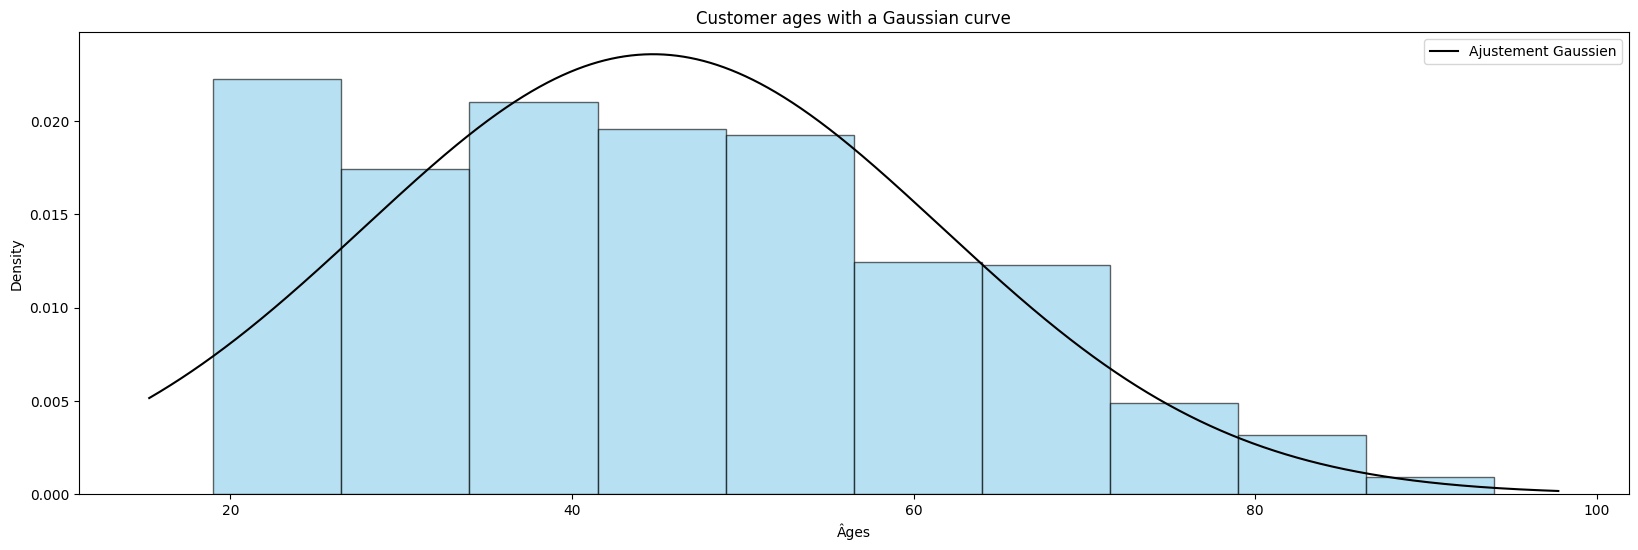

In [106]:
# Customer ages with a Gaussian curve
from scipy.stats import norm

plt.figure(figsize=(20, 6))
plt.hist(
    df_clients_correlation["age"],
    color="skyblue",
    density=True,
    edgecolor="black",
    alpha=0.6,
)
mu, std = norm.fit(df_clients_correlation["age"])
xmin, xmax = plt.xlim()
x = np.linspace(xmin, xmax, df_clients_correlation["age"].count())
p = norm.pdf(x, mu, std)
plt.plot(x, p, "k", label="Ajustement Gaussien")
plt.title("Customer ages with a Gaussian curve")
plt.xlabel("Âges")
plt.ylabel("Density")
plt.legend()
plt.show()

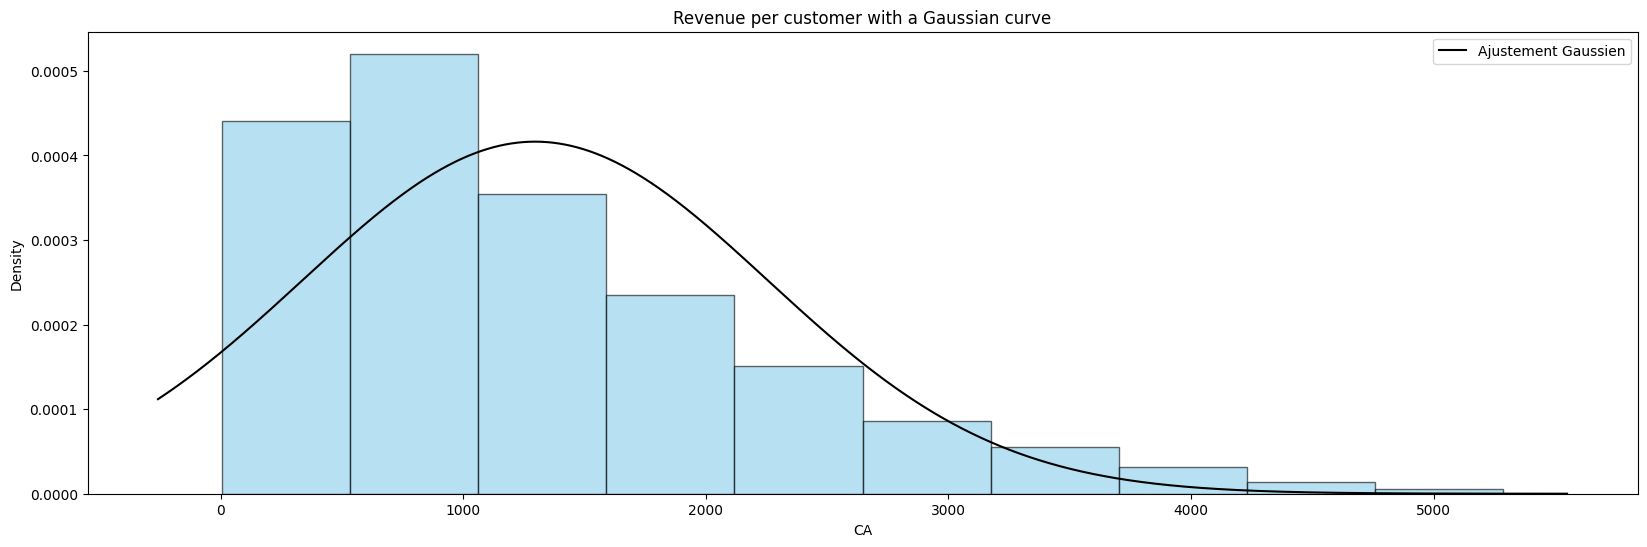

In [107]:
# Revenue per customer with a Gaussian curve
plt.figure(figsize=(20, 6))
plt.hist(
    df_clients_correlation["ca_total"],
    color="skyblue",
    density=True,
    edgecolor="black",
    alpha=0.6,
)
mu, std = norm.fit(df_clients_correlation["ca_total"])
xmin, xmax = plt.xlim()
x = np.linspace(xmin, xmax, df_clients_correlation["ca_total"].count())
p = norm.pdf(x, mu, std)
plt.plot(x, p, "k", label="Ajustement Gaussien")
plt.title("Revenue per customer with a Gaussian curve")
plt.xlabel("CA")
plt.ylabel("Density")
plt.legend()
plt.show()

Shapiro-Wilk test hypotheses:
- H0: the data follows a normal distribution
- H1: the data does not follow a normal distribution
- Significance level: alpha = 0.05

In [108]:
# Shapiro-Wilk test
from scipy.stats import shapiro

echantillon_age = df_clients_correlation["age"].sample(5000, random_state=42)
echantillon_ca = df_clients_correlation["ca_total"].sample(5000, random_state=42)

stat_age, p_value_age = shapiro(echantillon_age)
stat_ca, p_value_ca = shapiro(echantillon_ca)
print(
    f"Shapiro-Wilk statistic for age: {stat_age} with p-value {p_value_age}"
)
print(
    f"Shapiro-Wilk statistic for revenue per customer: {stat_ca} with p-value {p_value_ca}"
)
alpha = 0.05
if p_value_age > alpha and p_value_ca > alpha:
    print("The data is normally distributed: do not reject H0")
else:
    print("The data is not normally distributed: reject H0")

Shapiro-Wilk statistic for age: 0.9699883203154287 with p-value 4.112234219939646e-31
Shapiro-Wilk statistic for revenue per customer: 0.9060817827046617 with p-value 3.682988804699871e-48
The data is not normally distributed: reject H0


Conclusion:
The histograms show non-normal (non-Gaussian) profiles for both variables. Age is distributed fairly evenly, while revenue per customer is strongly right-skewed, concentrated on small amounts. The Shapiro-Wilk test confirms it, with p-values far below 0.05 (age: 4.11e-31, revenue: 3.68e-48). We reject H0: neither variable is normally distributed. Pearson's test is therefore not appropriate, and we use Spearman's test.

Spearman test hypotheses:
- H0: there is no correlation between a customer's age and total spend
- H1: there is a correlation between a customer's age and total spend
- Significance level: alpha = 0.05

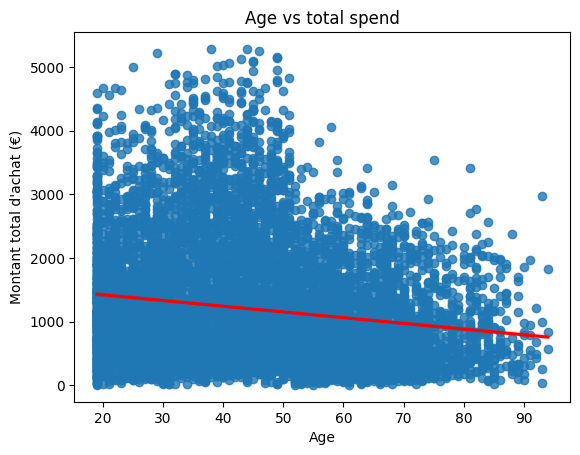

In [109]:
# Trend

sns.regplot(
    data=df_clients_correlation,
    x="age",
    y="ca_total",
    robust=True,
    line_kws=dict(color="r"),
)
plt.xlabel("Age")
plt.ylabel("Montant total d'achat (€)")
plt.title("Age vs total spend")
plt.show()

In [110]:
# Spearman test
from scipy.stats import spearmanr

spearman_corr_age_ca, spearman_p_value_age_ca = spearmanr(
    df_clients_correlation["age"], df_clients_correlation["ca_total"]
)
print(f"Spearman correlation coefficient: {spearman_corr_age_ca}")
print(f"p-value: {spearman_p_value_age_ca}")
alpha = 0.05
if spearman_p_value_age_ca < alpha:
    print("Reject H0: there is a correlation between the two variables")
else:
    print("Do not reject H0: no correlation between the two variables")

Spearman correlation coefficient: -0.18453796132936023
p-value: 1.0214367541093183e-66
Reject H0: there is a correlation between the two variables


Conclusion:
The scatter plot is very dispersed, with no visible structure. Customers aged 20 to 50 show more variability in spending, and the regression line shows a very slight downward trend.
The p-value (1.02e-66) is far below 0.05, so we reject H0: there is a link between the two variables that is not due to chance.
However, a link existing does not mean it is strong or relevant. The Spearman coefficient of -0.18 lies within [-0.25; +0.25], so the strength of the link is too weak to be considered. This micro-trend is marginal compared with the overall variability, and age cannot be considered a determining factor of spending.

<div style="border: 1px solid RGB(128, 0, 32);" >
<h3 style="margin: auto; padding: 20px; color: RGB(128, 0, 32); ">8.3 - Customer age vs purchase frequency</h3>
</div>

As before, the choice is between Pearson's and Spearman's tests. Age was shown not to be normally distributed, so we use Spearman's test for this correlation.

Spearman test hypotheses:
- H0: there is no correlation between a customer's age and purchase frequency
- H1: there is a correlation between a customer's age and purchase frequency
- Significance level: alpha = 0.05

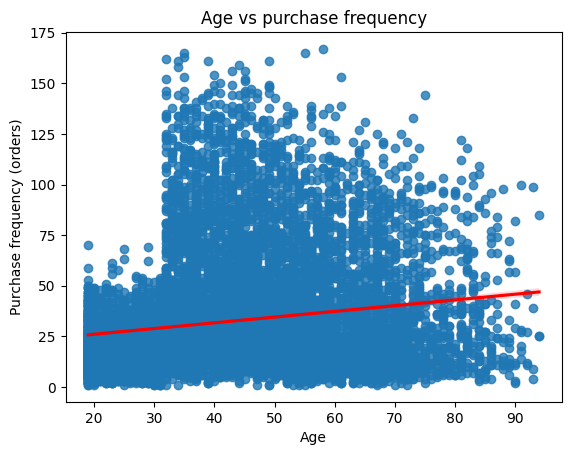

In [111]:
# Trend
sns.regplot(
    data=df_clients_correlation,
    x="age",
    y="nb_transactions",
    robust=True,
    line_kws=dict(color="r"),
)
plt.xlabel("Age")
plt.ylabel("Purchase frequency (orders)")
plt.title("Age vs purchase frequency")
plt.show()

In [112]:
# Spearman test
spearman_corr_age_frequence, spearman_p_value_age_frequence = spearmanr(
    df_clients_correlation["age"], df_clients_correlation["nb_transactions"]
)
print(f"Spearman correlation coefficient: {spearman_corr_age_frequence}")
print(f"p-value: {spearman_p_value_age_frequence}")
alpha = 0.05
if spearman_p_value_age_frequence < alpha:
    print("Reject H0: there is a correlation between the two variables")
else:
    print("Do not reject H0: no correlation between the two variables")

Spearman correlation coefficient: 0.21196373259671872
p-value: 6.629168433162731e-88
Reject H0: there is a correlation between the two variables


Conclusion:
The scatter plot is widely dispersed with no apparent logic, apart from a break around 30: the youngest customers (20 to 30) generally buy less often, never above 75 orders each, while dispersion increases sharply after 30, with customers above 100 or even 150 orders. The regression line, slightly upward, remains almost flat, suggesting a very weak relationship.
The p-value (6.62e-88) is far below 0.05, so we reject H0: the link is statistically reliable. However, the Spearman coefficient of 0.21 lies within [-0.25; +0.25], so the strength of the relationship is too small to be used. Age is not a relevant lever to explain purchase frequency.

<div style="border: 1px solid RGB(128, 0, 32);" >
<h3 style="margin: auto; padding: 20px; color: RGB(128, 0, 32); ">8.4 - Customer age vs average basket</h3>
</div>

As before, the choice is between Pearson's and Spearman's tests. Age was shown not to be normally distributed, so we use Spearman's test for this correlation.

Spearman test hypotheses:
- H0: there is no correlation between a customer's age and average basket
- H1: there is a correlation between a customer's age and average basket
- Significance level: alpha = 0.05

In [113]:
# Average basket column
df_clients_correlation["panier_moyen"] = (
    df_clients_correlation["ca_total"] / df_clients_correlation["nb_transactions"]
)

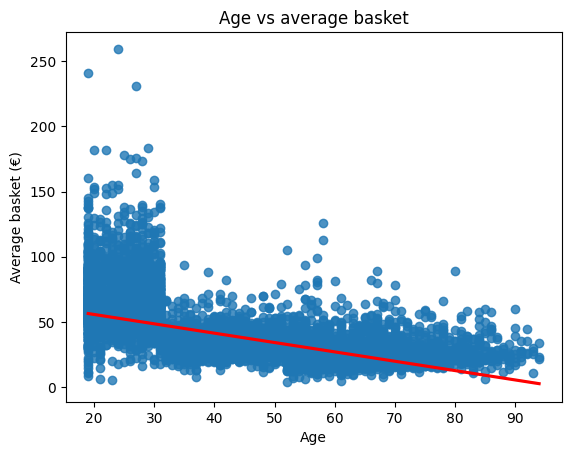

In [114]:
# Trend
sns.regplot(
    data=df_clients_correlation,
    x="age",
    y="panier_moyen",
    robust=True,
    line_kws=dict(color="r"),
)
plt.xlabel("Age")
plt.ylabel("Average basket (€)")
plt.title("Age vs average basket")
plt.show()

In [115]:
# Spearman test
spearman_corr_age_panier_moyen, spearman_p_value_age_panier_moyen = spearmanr(
    df_clients_correlation["age"], df_clients_correlation["panier_moyen"]
)
print(f"Spearman correlation coefficient: {spearman_corr_age_panier_moyen}")
print(f"p-value: {spearman_p_value_age_panier_moyen}")
alpha = 0.05
if spearman_p_value_age_panier_moyen < alpha:
    print("Reject H0: there is a correlation between the two variables")
else:
    print("Do not reject H0: no correlation between the two variables")

Spearman correlation coefficient: -0.7005505575689295
p-value: 0.0
Reject H0: there is a correlation between the two variables


Conclusion:
The scatter plot shows a clear downward trend: young customers (20 to 30) have very varied average baskets, some above €150 or even €250, while customers over 70 are grouped on smaller baskets, never above €100. The downward regression line reflects this negative relationship. The p-value of 0.0 lets us reject H0 with near-total confidence, and the Spearman coefficient (-0.70) confirms the downward trend. It lies within [-0.75; -0.50], a moderate negative correlation close to a strong one. Age is therefore a determining factor of a customer's average basket: the older the customer, the smaller the basket. This is a highly strategic lever for marketing:
- Target the under-30s for premium products, as they have the highest spending per order and premium products bring in the most revenue.
- Run loyalty campaigns for the under-30s to keep their spending level over time.
- Raise the basket of the over-30s with payment facilities (pay in 3, buy now pay later).
- Use upselling and cross-selling at the end of the customer journey for the over-30s to increase their basket.

<div style="border: 1px solid RGB(128, 0, 32);" >
<h3 style="margin: auto; padding: 20px; color: RGB(128, 0, 32); ">8.5 - Customer age vs book category</h3>
</div>

To test the link between a quantitative variable and a qualitative variable with 3 groups, we can use an ANOVA (if the data is normal) or a Kruskal-Wallis test (if it is not). Age is not normally distributed, so we use the Kruskal-Wallis test. However, the Central Limit Theorem states that with a large enough sample (n > 30), the distribution of sample means tends towards a normal distribution. Our sample (8,596) is large enough for the ANOVA to be robust to departures from normality, so we also run an ANOVA as a robustness check of the Kruskal-Wallis result.

In [116]:
# Add each customer's age to the main-category dataframe
df_age_clients = df_merge_transaction_products_customers[
    ["client_id", "age"]
].drop_duplicates()
df_categorie_principale_client = pd.merge(
    df_categorie_principale_client, df_age_clients, on="client_id", how="left"
)

Kruskal-Wallis test hypotheses:
- H0: the median age is the same for all book categories (age does not influence the category)
- H1: the median age differs for at least one category (age influences the category bought)
- Significance level: alpha = 0.05

In [117]:
# Kruskal-Wallis test
from scipy.stats import kruskal

cat_0 = df_categorie_principale_client[df_categorie_principale_client["categ"] == 0][
    "age"
]
cat_1 = df_categorie_principale_client[df_categorie_principale_client["categ"] == 1][
    "age"
]
cat_2 = df_categorie_principale_client[df_categorie_principale_client["categ"] == 2][
    "age"
]
kruskal_stat, kruskal_p_value = kruskal(cat_0, cat_1, cat_2)
print(f"Kruskal-Wallis statistic: {kruskal_stat}")
print(f"p-value: {kruskal_p_value}")
alpha = 0.05
if kruskal_p_value < alpha:
    print(
        "Reject H0: median age differs significantly by category"
    )
else:
    print(
        "Do not reject H0: median age is the same and does not influence the category bought"
    )

Kruskal-Wallis statistic: 2003.6681008920868
p-value: 0.0
Reject H0: median age differs significantly by category


ANOVA hypotheses:
- H0: the mean age is the same for all book categories
- H1: the mean age differs for at least one category
- Significance level: alpha = 0.05

In [118]:
# ANOVA
from scipy.stats import f_oneway

anova_stat, anova_p_value = f_oneway(cat_0, cat_1, cat_2)
print(f"ANOVA statistic: {anova_stat}")
print(f"p-value: {anova_p_value}")
alpha = 0.05
if anova_p_value < alpha:
    print(
        "Reject H0: mean age differs significantly by category"
    )
else:
    print(
        f"Do not reject H0: age does not influence the category bought."
    )

ANOVA statistic: 1201.7032223738279
p-value: 0.0
Reject H0: mean age differs significantly by category


In [119]:
# Age distribution by book category
fig = px.box(
    df_categorie_principale_client,
    x="categ",
    y="age",
    title="Customer age by book category",
    color="categ",
    color_discrete_sequence=["#2E8B57", "#A3334D", "#4169E1"],
)
fig.update_layout(
    xaxis_title="Book category",
    yaxis_title="Age",
    plot_bgcolor="white",
    xaxis=dict(showgrid=False),
    yaxis=dict(showgrid=False),
    showlegend=False,
)
fig.show()

Conclusion:
The Kruskal-Wallis and ANOVA tests agree perfectly: with p-values close to zero, below the significance level, we reject H0. The Kruskal-Wallis (2,003) and ANOVA (1,201) statistics confirm a significant difference in mean and median age between categories: a customer's age is linked to the category of books they buy. The boxplot shows three buyer profiles:
- category 0 attracts customers of all ages, centred around their forties;
- category 1 attracts a clearly older audience, with a median age close to 60, and the widest age range (19 to 94);
- category 2 mostly attracts buyers under 30, with a median age of 25.
Targets by category:
- category 0: general public
- category 1: seniors
- category 2: young adults